# CPSC 6440 01 / AMTH 3220 01 / CPSC 4844 01 / MATH 5220 01 / MATH 7440 01 FALL 2025 - Problem Set 1

Due date: September 25th

# Instructions:
- Save a copy of this notebook in your own Google Drive (Important!)
- Run each cell in sequence.
- Fill in the missing parts (marked as TODO).
- Test your implementation using the datasets provided.
- Submit your notebook as a .ipynb AND pdf to Gradescope


# Install Dependencies

IMPORTANT NOTE: When installing the dependencies, an error will appear and the runtime will crash and thats fine! Restart the runtime and run the imports code and it should work!

In [ ]:
!pip install phate gdown pandas==2.2.0

# Diffusion Maps

In [1]:
import numpy as np
import codecs, json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.decomposition import PCA
from sklearn.neighbors import kneighbors_graph
import networkx as nx
import community.community_louvain as community_louvain
import phate
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.cluster import SpectralClustering

In [2]:
def compute_distances(X):
    """
    Constructs a distance matrix from dataset X, assumes Euclidean distance.

    Inputs:
        X : numpy array of shape (n, p)
            Dataset with n samples and p features.

    Outputs:
        D : numpy array of shape (n, n)
            Pairwise Euclidean distances.
    """
    # TODO: Replace with your own implementation (hint: use euclidean_distances)
    return euclidean_distances(X)


In [3]:
def compute_affinity_matrix(D, kernel_type="gaussian", sigma=None, k=None, alpha=0):
    """
    Construct an affinity matrix from a distance matrix using a kernel.

    Inputs:
        D : numpy array of shape (n, n)
            Pairwise distances.
        kernel_type : str, "gaussian" or "adaptive"
        sigma : float
            Gaussian kernel parameter (if kernel_type="gaussian")
        k : int
            Adaptive kernel parameter (if kernel_type="adaptive")
        alpha : float
            Normalization exponent

    Outputs:
        W : numpy array of shape (n, n)
            Affinity (similarity) matrix.
    """

    # TODO: Implement Gaussian kernel:
    #   W[i,j] = exp(- D[i,j]^2 / (2 * sigma^2))
    # TODO: Implement adaptive kernel using kth nearest neighbor distances.
    # TODO: Normalize with parameter alpha.
    if kernel_type == "gaussian":
        W = np.exp(-D**2 / (2 * sigma**2))
    elif kernel_type == "adaptive":
        # Find the k-th nearest neighbor distance for each point
        k_distances = np.sort(D, axis=1)[:, k]
        # Create epsilon matrix: epsilon[i,j] = (d_ki + d_kj) / 2
        epsilon_matrix = (k_distances[:, np.newaxis] + k_distances[np.newaxis, :]) / 2
        # Apply Gaussian kernel with adaptive bandwidth: exp(-D[i,j]^2 / (2 * epsilon[i,j]^2))
        W = np.exp(-D**2 / (2 * epsilon_matrix**2))
    else:
        raise ValueError("kernel_type must be 'gaussian' or 'adaptive'.")

    # Density normalization with alpha
    d = np.sum(W, axis=1)
    d_alpha = np.power(d, -alpha)
    W = W * np.outer(d_alpha, d_alpha)

    return W

In [4]:
def diff_map_info(W):
    """
    Compute the eigenvectors and eigenvalues for diffusion maps.

    Inputs:
        W : numpy array of shape (n, n)
            Affinity matrix.

    Outputs:
        diff_vec : numpy array (n, n-1)
            Nontrivial eigenvectors of Markov matrix.
        diff_eig : numpy array (n-1,)
            Nontrivial eigenvalues.
    """

    # TODO: Construct normalized matrix M_s
    # TODO: Check symmetry
    # TODO: Compute eigen decomposition
    # TODO: Normalize eigenvectors
    # TODO: Return (diff_vec, diff_eig)

    # Normalize W to create the Markov matrix P
    d = np.sum(W, axis=1)
    P = W / d[:, np.newaxis]

    # Compute eigenvalues and eigenvectors
    eigenvalues, eigenvectors = np.linalg.eig(P)

    # Sort eigenvalues and eigenvectors in descending order
    sorted_indices = np.argsort(eigenvalues)[::-1]
    diff_eig = eigenvalues[sorted_indices]
    diff_vec = eigenvectors[:, sorted_indices]

    # Discard the first eigenvector and eigenvalue as it is trivial
    return diff_vec[:, 1:], diff_eig[1:]


In [5]:
def get_diff_map(diff_vec, diff_eig, t):
    """
    Construct diffusion map embedding at diffusion time t.

    Inputs:
        diff_vec : numpy array (n, n-1)
            Eigenvectors of Markov matrix.
        diff_eig : numpy array (n-1,)
            Eigenvalues of Markov matrix.
        t : int
            Diffusion time.

    Outputs:
        diff_map : numpy array (n, n-1)
            Diffusion map embedding.
    """

    # TODO: Multiply eigenvectors by eigenvalues^t
    return diff_vec * (diff_eig**t)


In [6]:
def plot_diff_map(diff_map, labels=None, title_str=None):
    """
    Plot pairwise diffusion map coordinates.

    Inputs:
        diff_map : numpy array (n, n-1)
            Diffusion map embedding.
        labels : optional, array of shape (n,)
            Labels for coloring points.
        title_str : optional, str
            Title of plot.
    """
    plt.figure(figsize=(8, 8))
    plt.scatter(diff_map[:,0], diff_map[:,1], c=labels, cmap="viridis", alpha=0.6)
    plt.xlabel("v1")
    plt.ylabel("v2")
    if title_str:
        plt.title(title_str)
    plt.show()


We can now test if the diffusion map you implemented above works for a toy swiss roll dataset before we move on to a real world dataset.

/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/matplotlib/collections.py:200: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


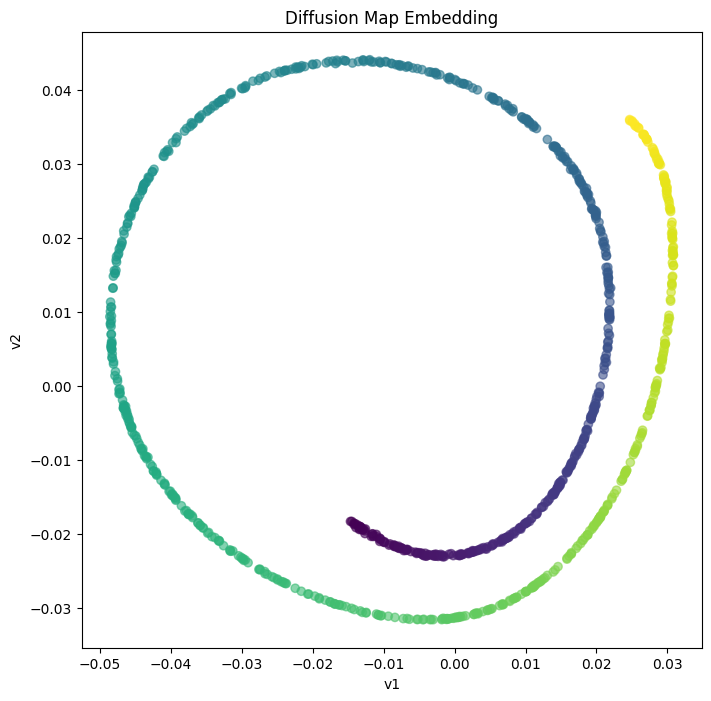

In [7]:
from sklearn.datasets import make_swiss_roll

# Generate dataset
X, labels = make_swiss_roll(n_samples=1000, noise=0.05)
X = X[:, [0, 2]]  # take 2D slice for simplicity or (also look into 3D plotting)

# Compute diffusion maps
D = compute_distances(X)
W = compute_affinity_matrix(D, kernel_type="gaussian", sigma=5.0)
diff_vec, diff_eig = diff_map_info(W)
diff_map = get_diff_map(diff_vec, diff_eig, t=1)

# Plot
plot_diff_map(diff_map, labels, "Diffusion Map Embedding")


# iPSC Reprogramming Dataset

Here we will load the iPSC dataset as described in the Assignment.

In [8]:
def load_json_files(file_path):
    '''
    Loads data from a json file

    Inputs:
        file_path   the path of the .json file that you want to read in

    Outputs:
        json_data    this is a numpy array if data is numeric, it's a list if it's a string

    '''

    #  load data from json file
    with codecs.open(file_path, 'r', encoding='utf-8') as handle:
        json_data = json.loads(handle.read())

    # if a string, then returns list of strings
    if not isinstance(json_data[0], str):
        # otherwise, it's assumed to be numeric and returns numpy array
        json_data = np.array(json_data)

    return json_data

If you are running this notebook on Google Colab (as recommended), the below snippet of code will help you fetch the iPSC data files from a shared Google Drive. Please run it as is.

If you are running this notebook locally, you can find the iPSC data files on Canvas and directly load them using the ```load_json_files``` function defined for you above.



In [9]:
import gdown

file_id_data = "1TPcg8-MMTgUvRaAQvVosWWFkrCA8ebCd"
file_id_channel = "1xfZa62hlF_DxjIi4qxNOaXaTyHZIRj5N"

url_data = f"https://drive.google.com/uc?id={file_id_data}"
url_channel = f"https://drive.google.com/uc?id={file_id_channel}"

output_data = "ipsc_data.json"
output_channel = "ipsc_channel_data.json"

gdown.download(url_data, output_data, quiet=False)
gdown.download(url_channel, output_channel, quiet=False)

print("Download complete!")


Downloading...
From: https://drive.google.com/uc?id=1TPcg8-MMTgUvRaAQvVosWWFkrCA8ebCd
To: /Users/annasu/Library/CloudStorage/OneDrive-YaleUniversity/Year 4/Classes/CPSC 6440/HW/PS1/ipsc_data.json
100%|████████████████████████| 1.12M/1.12M [00:00<00:00, 7.86MB/s]
Downloading...
From: https://drive.google.com/uc?id=1xfZa62hlF_DxjIi4qxNOaXaTyHZIRj5N
To: /Users/annasu/Library/CloudStorage/OneDrive-YaleUniversity/Year 4/Classes/CPSC 6440/HW/PS1/ipsc_channel_data.json
100%|█████████████████████████████| 290/290 [00:00<00:00, 684kB/s]

Download complete!


In [10]:
#Load the iPSC dataset
ipsc_data = load_json_files('ipsc_data.json')
ipsc_channel_names = load_json_files('ipsc_channel_data.json')
time_steps = np.arange(ipsc_data.shape[0])

# Visualizing Data with Diffusion Maps

In this section, we will visualize the data using Diffusion Maps and see what changes. Here, your task will be to
1. Construct the affinity matrix of the iPSC data set using euclidean distance and adaptive k-nearest
neighbors Gaussian kernel with k = 2 and diffusion parameter t = 1.
2. Create two-dimensional scatter plots of the diffusion mapping using different coordinates.
3. Create three-dimensional scatter plot of the diffusion mapping using the first three coordinates for
plotting. Color the points with their corresponding timepoint values.
4. Plot the associated eigenvalues of the Markov matrix.
5. Compute the top 5 channels that have the highest absolute correlation with the first, second, and third
diffusion components.

In [11]:
# TODO: Construct the affinity matrix of the iPSC dataset with the parameters specified above and plot the diffusion map. You may use the functions you defined earlier in this notebook.
D_ipsc = compute_distances(ipsc_data)
W_ipsc = compute_affinity_matrix(D_ipsc, kernel_type="adaptive", k=2, alpha=1)

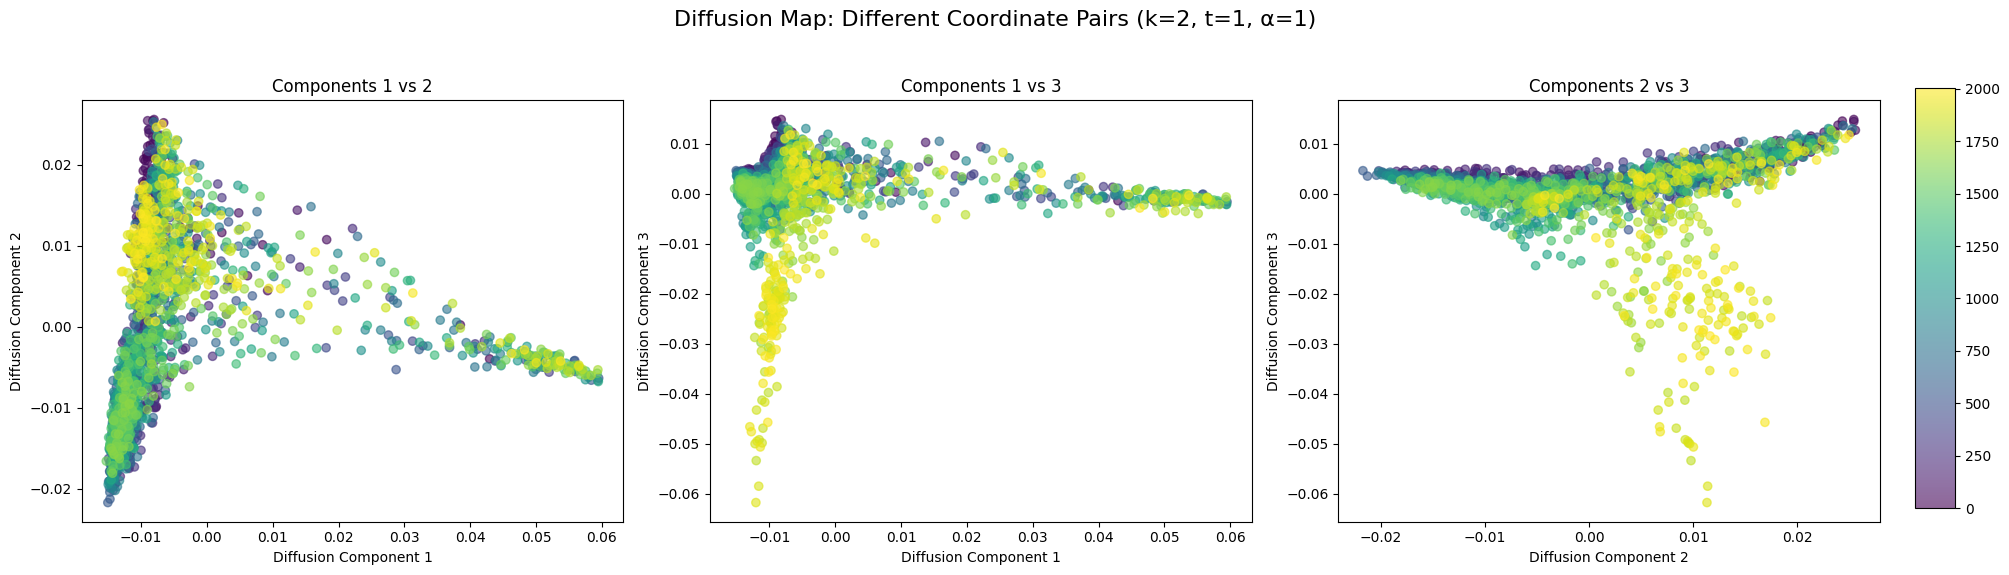

In [12]:
# TODO: Create two-dimensional scatter plots of the diffusion mapping using different coordinates (e.g., (1,2), (1,3), (2,3), etc.).
# You may use the plotting function defined in the diffusion map section.
diff_vec_ipsc, diff_eig_ipsc = diff_map_info(W_ipsc)
diff_map_ipsc = get_diff_map(diff_vec_ipsc, diff_eig_ipsc, t=1)


# Spoken to TA about defining my own plotting function to show multiple subplots and color maps at once
def plot_diff_map_2d(diff_map, k, t, alpha):
    # Define the pairs of coordinates to plot
    coord_pairs = [(1, 2), (1, 3), (2, 3)]

    # Create a figure with subplots (1 row, 3 columns)
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(f"Diffusion Map: Different Coordinate Pairs (k={k}, t={t}, \u03B1={alpha})", fontsize=16)

    # Loop through the coordinate pairs and create a plot for each subplot
    for idx, (i, j) in enumerate(coord_pairs):
        ax = axes[idx]
        scatter = ax.scatter(diff_map[:, i-1], diff_map[:, j-1], c=time_steps, cmap="viridis", alpha=0.6)
        ax.set_xlabel(f"Diffusion Component {i}")
        ax.set_ylabel(f"Diffusion Component {j}")
        ax.set_title(f"Components {i} vs {j}")


    fig.tight_layout(rect=[0, 0.03, 0.95, 0.95])
    cbar_ax = fig.add_axes([0.96, 0.15, 0.02, 0.7])
    fig.colorbar(scatter, cax=cbar_ax)
    plt.show()
    
plot_diff_map_2d(diff_map_ipsc, 2, 1, 1)

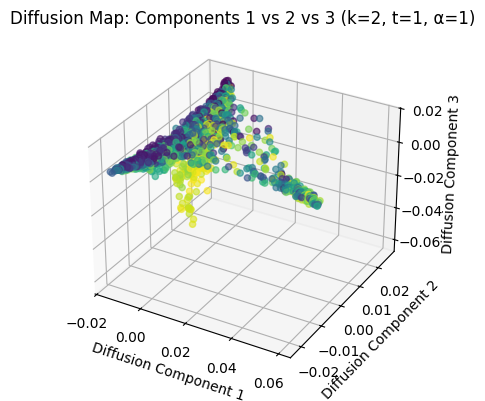

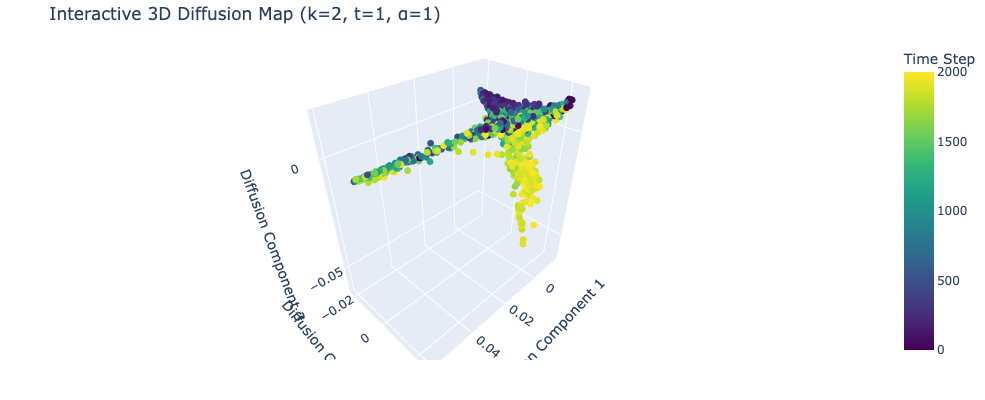

In [13]:
# TODO: Create a three-dimensional scatter plot of the diffusion mapping using the first three coordinates for plotting and color the points with their corresponding timepoint values.
# You may use the plotting function defined in the diffusion map section.
def plot_diff_map_3d(diff_map, k, t, alpha):
    fig = plt.figure(figsize=(5, 4))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(diff_map[:,0], diff_map[:, 1], diff_map[:, 2], c=time_steps, cmap="viridis", alpha=0.6)
    ax.set_xlabel(f"Diffusion Component 1", labelpad=3)
    ax.set_ylabel(f"Diffusion Component 2", labelpad=3)
    ax.set_zlabel(f"Diffusion Component 3", labelpad=3)
    ax.set_title(f"Diffusion Map: Components 1 vs 2 vs 3 (k={k}, t={t}, \u03B1={alpha})")
    plt.tight_layout()
    plt.show()
plot_diff_map_3d(diff_map_ipsc, 2, 1, 1)


import plotly.express as px
def plot_diff_map_3d_interact(diff_map, k, t, alpha):
    fig = px.scatter_3d(
        x=diff_map[:, 0],
        y=diff_map[:, 1],
        z=diff_map[:, 2],
        color=time_steps,
        labels={
            'x': 'Diffusion Component 1',
            'y': 'Diffusion Component 2',
            'z': 'Diffusion Component 3',
            'color': 'Time Step'
        },
        title=f'Interactive 3D Diffusion Map (k={k}, t={t}, \u03B1={alpha})',
        color_continuous_scale=px.colors.sequential.Viridis,
        width=500, height=400
    )
    fig.update_layout(
        margin=dict(l=40, r=0, b=40, t=40)
    )
    fig.update_traces(marker=dict(size=4))
    fig.show()

plot_diff_map_3d_interact(diff_map_ipsc, 2, 1, 1)


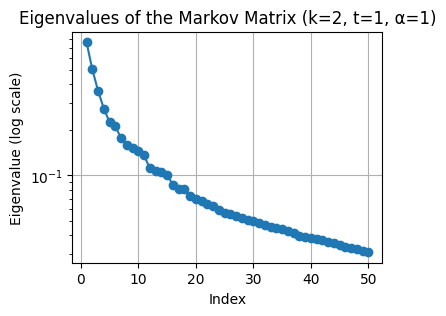

In [14]:
# TODO: Plot the associated eigenvalues of the Markov matrix.
def plot_eigenvalues(eigenvals, k, t, alpha):
    plt.figure(figsize=(4, 3))
    plt.plot(np.arange(1, len(eigenvals[:50]) + 1), eigenvals[:50], marker='o')
    plt.yscale('log')
    plt.xlabel('Index')
    plt.ylabel('Eigenvalue (log scale)')
    plt.title(f'Eigenvalues of the Markov Matrix (k={k}, t={t}, \u03B1={alpha})')
    plt.grid(True)
    plt.show()
plot_eigenvalues(diff_eig_ipsc, 2, 1, 1)

In [15]:
# TODO: Compute the top 5 channels that have the highest absolute correlation with the first, second, and third diffusion components.
# Hint: Compute Pearson correlation between each channel (column of X) and each of the first 3 diffusion components (columns of DM[:, :3]).
from scipy.stats import pearsonr

def get_top_channels(data, channel_names, diff_map, k, t, alpha, top_n):
    print(f"\nGetting top {top_n} channels (k={k}, t={t}, \u03B1={alpha}):")
    top_channels = {}
    for i in range(3):  # For the first three diffusion components
        correlations = []
        for j in range(data.shape[1]):  # For each channel
            corr, _ = pearsonr(data[:, j], diff_map[:, i])
            correlations.append((channel_names[j], abs(corr)))
        # Sort by absolute correlation and take the top 5
        correlations.sort(key=lambda x: x[1], reverse=True)
        top_channels[f'Diffusion Component {i+1}'] = correlations[:top_n]
    for component, channels in top_channels.items():
        print(f"\n--- Top 5 channels for {component}:")
        for channel, corr in channels:
            print(f"* Channel: {channel}, Absolute Correlation: {corr:.4f}")

get_top_channels(ipsc_data, ipsc_channel_names, diff_map_ipsc, 2, 1, 1, 5)


Getting top 5 channels (k=2, t=1, α=1):

--- Top 5 channels for Diffusion Component 1:
* Channel: h3k9ac, Absolute Correlation: 0.8168
* Channel: prb, Absolute Correlation: 0.7960
* Channel: pplk1, Absolute Correlation: 0.7462
* Channel: pstat3-727, Absolute Correlation: 0.6688
* Channel: pampk, Absolute Correlation: 0.6393

--- Top 5 channels for Diffusion Component 2:
* Channel: oct4, Absolute Correlation: 0.7384
* Channel: mefsk4, Absolute Correlation: 0.6265
* Channel: cd140a, Absolute Correlation: 0.6171
* Channel: bcatenin, Absolute Correlation: 0.5985
* Channel: thy1, Absolute Correlation: 0.5020

--- Top 5 channels for Diffusion Component 3:
* Channel: lin28, Absolute Correlation: 0.5968
* Channel: epcam, Absolute Correlation: 0.5815
* Channel: ssea1, Absolute Correlation: 0.5713
* Channel: cd44, Absolute Correlation: 0.4389
* Channel: mefsk4, Absolute Correlation: 0.4189


# Changing Parameters

In this section, we’ll examine how changing parameters affects the iPSC data set. Your tasks will be
1. Try two different values of diffusion parameter t and visualize the embeddings and the eigenvalues.
2. Try two different values of k for the adaptive kernel and visualize the embeddings and the eigenvalues.
3. For every choice of parameters above, compute the top 5 channels that have the highest absolute
correlation with the first, second, and third diffusion components.

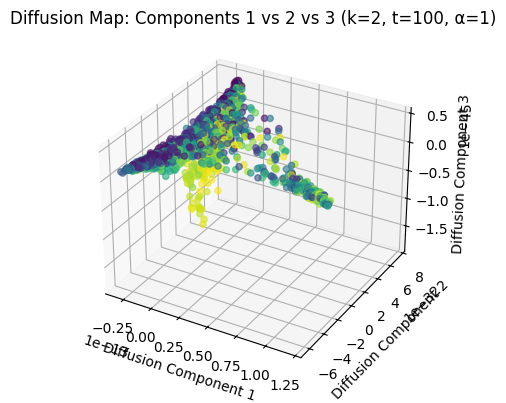

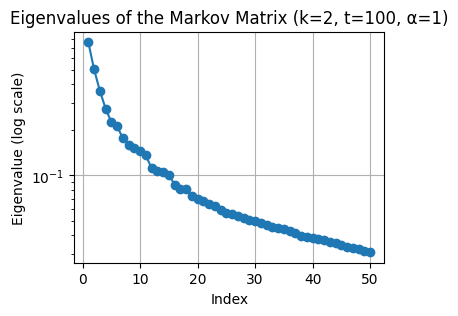

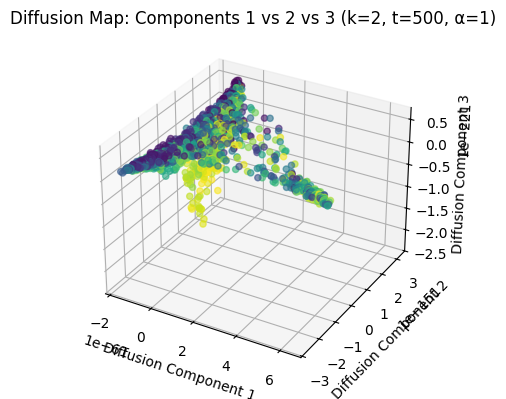

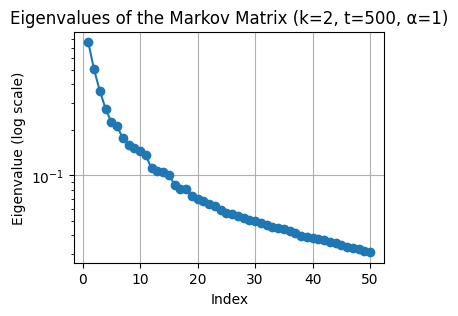

In [16]:
# TODO: Try two different values of diffusion parameter t and visualize the embeddings and the eigenvalues. You may use the functions defined earlier in this notebook.
T = [100, 500]
for t in T:
    diff_map_ipsc = get_diff_map(diff_vec_ipsc, diff_eig_ipsc, t=t)
    plot_diff_map_3d(diff_map_ipsc, 2, t, 1)
    plot_eigenvalues(diff_eig_ipsc, 2, t, 1)

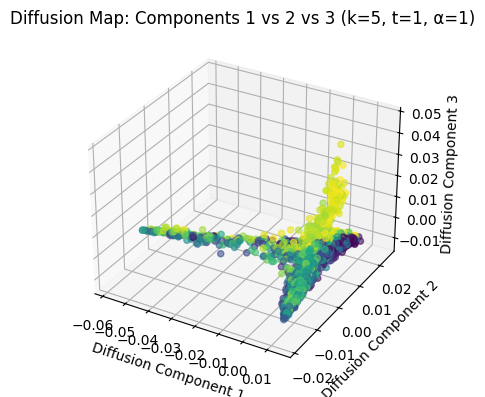

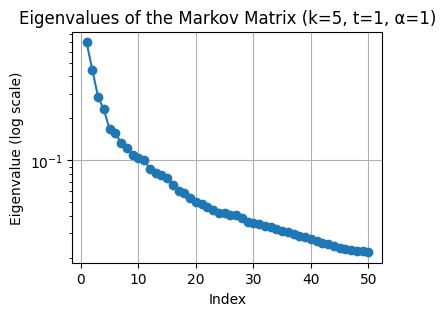

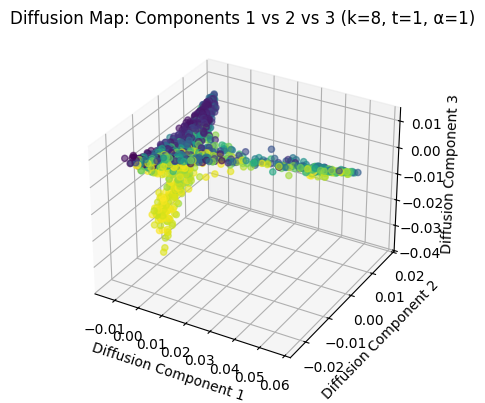

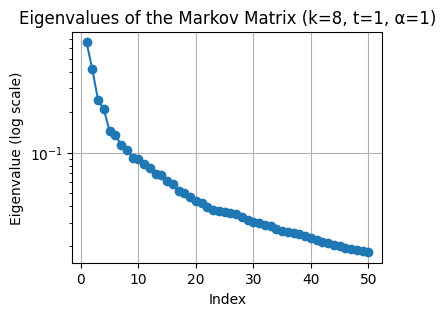

In [17]:
# TODO: Try two different values of k for the adaptive kernel and visualize the embeddings and the eigenvalues. You may use the functions defined earlier in this notebook.
K = [5, 8]
for k in K:
    W_ipsc = compute_affinity_matrix(D_ipsc, kernel_type="adaptive", k=k, alpha=1.0)
    diff_vec_ipsc, diff_eig_ipsc = diff_map_info(W_ipsc)
    diff_map_ipsc = get_diff_map(diff_vec_ipsc, diff_eig_ipsc, t=1)
    plot_diff_map_3d(diff_map_ipsc, k, 1, 1)
    plot_eigenvalues(diff_eig_ipsc, k, 1, 1)

In [18]:
# TODO: For every choice of the parameters above, compute the top 5 channels that have the highest absolute correlation with the first, second, and third diffusion components.
for t in T:
    for k in K:
        W_ipsc = compute_affinity_matrix(D_ipsc, kernel_type="adaptive", k=k, alpha=1.0)
        diff_vec_ipsc, diff_eig_ipsc = diff_map_info(W_ipsc)
        diff_map_ipsc = get_diff_map(diff_vec_ipsc, diff_eig_ipsc, t=t)
        get_top_channels(ipsc_data, ipsc_channel_names, diff_map_ipsc, k, t, 1, 5)


Getting top 5 channels (k=5, t=100, α=1):

--- Top 5 channels for Diffusion Component 1:
* Channel: h3k9ac, Absolute Correlation: 0.8168
* Channel: prb, Absolute Correlation: 0.7973
* Channel: pplk1, Absolute Correlation: 0.7454
* Channel: pstat3-727, Absolute Correlation: 0.6664
* Channel: pampk, Absolute Correlation: 0.6401

--- Top 5 channels for Diffusion Component 2:
* Channel: oct4, Absolute Correlation: 0.7284
* Channel: mefsk4, Absolute Correlation: 0.6307
* Channel: cd140a, Absolute Correlation: 0.6222
* Channel: bcatenin, Absolute Correlation: 0.6092
* Channel: thy1, Absolute Correlation: 0.5124

--- Top 5 channels for Diffusion Component 3:
* Channel: lin28, Absolute Correlation: 0.6041
* Channel: epcam, Absolute Correlation: 0.5991
* Channel: ssea1, Absolute Correlation: 0.5682
* Channel: cd44, Absolute Correlation: 0.4388
* Channel: mefsk4, Absolute Correlation: 0.4165

Getting top 5 channels (k=8, t=100, α=1):

--- Top 5 channels for Diffusion Component 1:
* Channel: h3k

# Comparing Visualizations

Lets compare the diffusion maps visualization to that of PHATE and tSNE
1. Run PHATE and tSNE on the on the processed iPSC data set singular values.
2. Plot the iPSC data set in two dimensions, using PHATE and tSNE color them using the time steps.

In [19]:
#Run PHATE and tSNE on the iPSC data. You may use the PHATE and tSNE packages.

phate_operator = phate.PHATE()
ipsc_data_phate = phate_operator.fit_transform(ipsc_data)

tsne_operator = TSNE(n_components=2, perplexity=30)
ipsc_data_tsne = tsne_operator.fit_transform(ipsc_data)

Calculating PHATE...
  Running PHATE on 2005 observations and 33 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 0.10 seconds.
    Calculating affinities...
  Calculated graph and diffusion operator in 0.13 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 0.43 seconds.
    Calculating KMeans...
    Calculated KMeans in 1.80 seconds.
  Calculated landmark operator in 2.33 seconds.
  Calculating optimal t...
    Automatically selected t = 17
  Calculated optimal t in 2.15 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.67 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 1.71 seconds.
Calculated PHATE in 7.19 seconds.


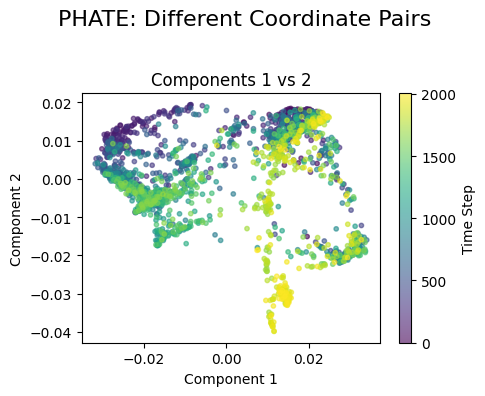

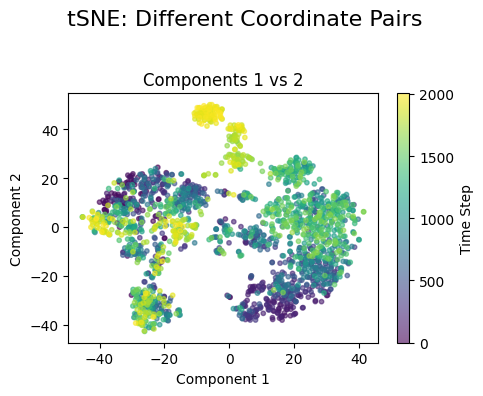

In [20]:
# TODO: Plot the iPSC data set in two dimensions, using PHATE and tSNE color them using the time steps.
def plot_2d(data_red, dim_red_method):
    plt.figure(figsize=(5, 4))
    plt.suptitle(f"{dim_red_method}: Different Coordinate Pairs", fontsize=16)

    ax = plt.gca()
    scatter = ax.scatter(data_red[:, 0], data_red[:, 1], c=time_steps, cmap="viridis", alpha=0.6, s=10)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.set_title("Components 1 vs 2")

    plt.tight_layout(rect=[0, 0, 0.95, 0.95])
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('Time Step')
    plt.show()

plot_2d(ipsc_data_phate, "PHATE")
plot_2d(ipsc_data_tsne, "tSNE")


# Clustering the iPSC Data with Louvain

In this section, we will explore Louvain clustering. Your task is to apply the Louvain algorithm to the iPSC dataset:
1. Construct a k-nearest neighbor graph from the iPSC data using Euclidean distances between cells.
2. Apply the Louvain algorithm to cluster cells based on this graph.
3. Report the number of clusters found and approximate size of each cluster.
4. Create a two-dimensional scatter plot using your diffusion map embedding from earlier and color the
points by their Louvain clusters.

In [21]:
# TODO: Construct a k-nearest neighbors graph from the data. You may use sklearn to construct the graph.
k = 10  # You can change this value to try different numbers of neighbors

knn_graph = kneighbors_graph(ipsc_data, n_neighbors=k, mode='connectivity', include_self=False)
G = nx.from_scipy_sparse_array(knn_graph)  # unweighted edges
print("Graph:", G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")

Graph: 2005 nodes, 15392 edges


In [22]:
# TODO: Apply the Louvain algorithm to cluster cells based on the graph defined above and report the number of clusters found and approximate size of each cluster.

partition = community_louvain.best_partition(G)

# Dict -> label array (ordered by node id)
labels = np.array([partition[i] for i in sorted(G.nodes())])

# Report
unique, counts = np.unique(labels, return_counts=True)
order = np.argsort(-counts)

print(f"Number of clusters found: {len(unique)}")
print("Approximate size of each cluster:")
for i in order:
    print(f"Cluster {unique[i]}: {counts[i]} cells")

Number of clusters found: 12
Approximate size of each cluster:
Cluster 1: 339 cells
Cluster 9: 304 cells
Cluster 8: 263 cells
Cluster 5: 222 cells
Cluster 2: 221 cells
Cluster 0: 181 cells
Cluster 11: 98 cells
Cluster 6: 96 cells
Cluster 4: 93 cells
Cluster 3: 87 cells
Cluster 7: 81 cells
Cluster 10: 20 cells


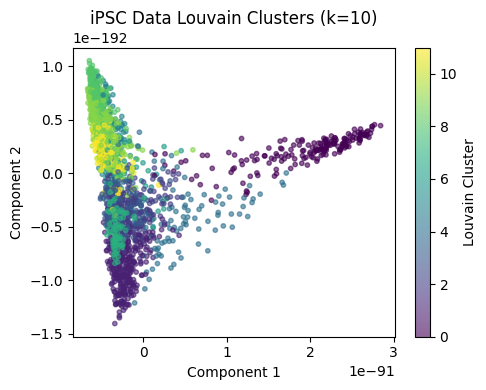

In [23]:
# TODO: Create a two-dimensional scatter plot of the diffusion mapping embeddings from earlier and color the points with their corresponding Louvain cluster labels.
def plot_diff_map_louvain(diff_map, labels, k, cluster_method):
    plt.figure(figsize=(5, 4))
    plt.scatter(diff_map[:,0], diff_map[:,1], c=labels, cmap="viridis",alpha=0.6, s=10)
    plt.xlabel("Component 1")
    plt.ylabel("Component 2")
    plt.title(f"iPSC Data {cluster_method} Clusters (k={k})")
    plt.colorbar(label=f'{cluster_method} Cluster')
    plt.tight_layout()
    plt.show()
plot_diff_map_louvain(diff_map_ipsc, labels, 10, "Louvain")

# Comparing Clustering Methods

We will next cluster this dataset using k-means and spectral clustering.
1. Use the diffusion components you computed in part 3.1 of this homework.
2. Draw a screenplot of the eigenvalues of the diffusion operator.
3. Choose an appropriate k, for the k-means.
4. Apply k-means to the raw data, as well as to k diffusion components.
5. Visualize the clusters as a coloring on top of the visuals you developed in part 3.3.

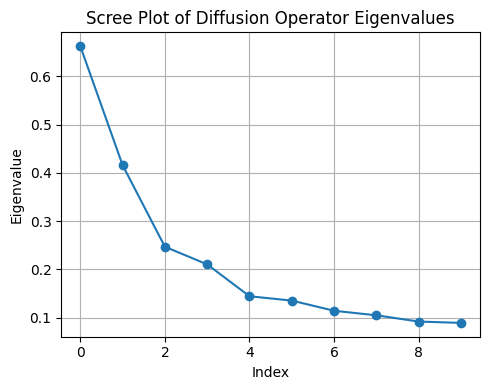

In [24]:
# TODO: Draw a scree plot of the eigenvalues of the diffusion operator.
def plot_eigenvalue_scree(eigenvalues):
    plt.figure(figsize=(5, 4))
    plt.plot(eigenvalues, marker='o')
    plt.xlabel("Index")
    plt.ylabel("Eigenvalue")
    plt.title("Scree Plot of Diffusion Operator Eigenvalues")
    plt.grid()
    plt.tight_layout()
    plt.show()
plot_eigenvalue_scree(diff_eig_ipsc[:10])

In [25]:
# TODO: Choose an appropriate k, for the k-means and apply k-means to the raw data,
# as well as to k diffusion components.
# You may use sklearn's KMeans package: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
k = 10

# Apply k-means to the raw data
kmeans_raw = KMeans(n_clusters=k, random_state=42)
labels_raw = kmeans_raw.fit_predict(ipsc_data)

# Apply k-means to the diffusion components
kmeans_diff = KMeans(n_clusters=k, random_state=42)
labels_diff = kmeans_diff.fit_predict(diff_map_ipsc)

In [26]:
# TODO: Apply spectral clustering to the raw data, as well as to k diffusion components.
# You may use sklearn's SpectralClustering package: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.SpectralClustering.html
# spec = SpectralClustering(n_clusters=k, affinity='nearest_neighbors', n_neighbors=5, random_state=42)
# labels_spec_raw = spec.fit_predict(ipsc_data)
# labels_spec_diff = spec.fit_predict(diff_map_ipsc)

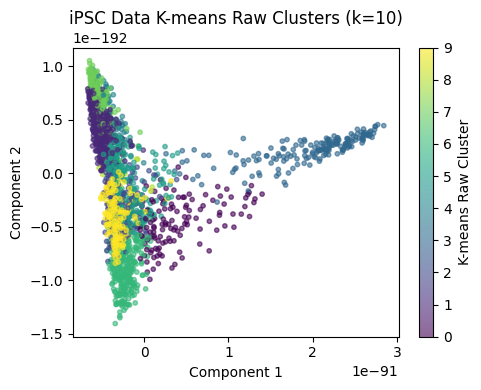

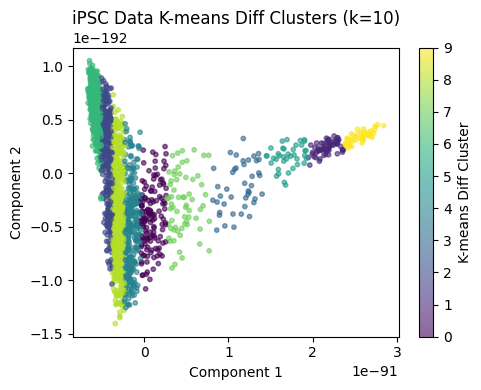

In [27]:
# TODO: Visualize the clusters as a coloring on top of the visuals you developed in part 3.3. Simply call the plot_diff_map function defined earlier with the appropriate labels.
plot_diff_map_louvain(diff_map_ipsc, labels_raw, 10, "K-means Raw")
plot_diff_map_louvain(diff_map_ipsc, labels_diff, 10, "K-means Diff")
# plot_diff_map_louvain(diff_map_ipsc, labels_spec_raw, 10, "Spectral Clustering Raw")
# plot_diff_map_louvain(diff_map_ipsc, labels_spec_diff, 10, "Spectral Clustering Diff")